In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
from skimage.transform import downscale_local_mean

In [3]:
path = "/home/kushal/repos/td-svd-sandbox/dendrites_rect.tif"

movie = tifffile.imread(path)#[:, ::2, ::2]

# Convert the data type to float32
movie = movie.astype(np.float32)

In [4]:
movie.shape

(19999, 55, 53)

In [5]:
movie = movie[:10_000]

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
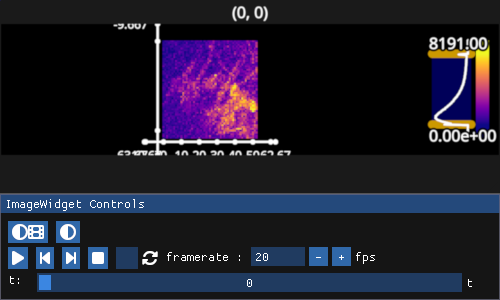

In [6]:
fpl.ImageWidget(movie).show()

In [7]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie).T

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [8]:
n_pixels = X.shape[1]
n_time_steps = X.shape[0]

# P = np.zeros((n_time_steps,n_pixels-1))
# F = np.zeros((n_time_steps,n_pixels-1))3
# for col in range(0,n_pixels-1):
#     P[:,col] = X[:,col]
#     F[:,col] = X[:,col+1]

P = np.zeros((n_time_steps-1,n_pixels))
F = np.zeros((n_time_steps-1,n_pixels))
for row in range(0,n_time_steps-1):
    P[row,:] = X[row,:]
    F[row,:] = X[row+1,:]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
print (f"F.shape = {F.shape}")

X.shape = (10000, 2915)
P.shape = (9999, 2915)
F.shape = (9999, 2915)


In [9]:
def centered_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    X_mean = X.mean(axis=1, keepdims=True) # has a shape of T x 1
    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

In [10]:
Pc = centered_matrix(P)
Fc = centered_matrix(F)

X_mean.shape = (9999, 1)
X_mean.shape = (9999, 1)


In [11]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [12]:
def covariance_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    N = X.shape[1]
    COV = X.T @ X / float(N)
    
    return COV

In [13]:
def whitened_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    COV = covariance_matrix(X)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix
    W = U @ inv_sqrt_S @ U.T

    # whitened data
    Xw = X @ W

    return Xw

In [14]:
Pw = whitened_matrix(P)
Fw = whitened_matrix(F)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw)
print (COV)

eigenvectors.shape = (2915, 2915)
eigenvectors.shape = (2915, 2915)
P.shape = (9999, 2915)
Pw.shape = (9999, 2915)
[[ 1.00000000e+00 -1.43147094e-11 -1.30211589e-11 ... -4.05908202e-13
  -8.02852353e-13  5.44168332e-13]
 [-1.43147094e-11  1.00000000e+00 -2.29506698e-12 ... -5.59911149e-12
   2.20200195e-12  1.54399370e-12]
 [-1.30211589e-11 -2.29506698e-12  1.00000000e+00 ...  1.59090747e-12
  -4.61039249e-13 -1.79477550e-14]
 ...
 [-4.05908202e-13 -5.59911149e-12  1.59090747e-12 ...  1.00000000e+00
  -7.69568057e-13 -1.79602283e-13]
 [-8.02852353e-13  2.20200195e-12 -4.61039249e-13 ... -7.69568057e-13
   1.00000000e+00  3.03244527e-13]
 [ 5.44168332e-13  1.54399370e-12 -1.79477550e-14 ... -1.79602283e-13
   3.03244527e-13  1.00000000e+00]]


In [15]:
Z = np.hstack((Pw, Fw))
ZTZ = Z.T @ Z

In [22]:
k = 16

In [23]:
H_init = 2 * np.sqrt(np.mean(np.mean(ZTZ) / k)) * np.random.rand(ZTZ.shape[0], k)

In [25]:
from tqdm.notebook import tqdm

eta = 5e-1
error_stop = 1e-4
error_log = np.zeros(20_000)

Y = H_init.T
# Y = np.abs(Sk @ Uk.T)

epsilon = 1e-5
epsilon_mtx = np.ones_like(Y@Y.T@Y) * epsilon

beta = 0.01
# beta = 1.0
# beta = 100.300300300300
for n_iter in tqdm(range(1_000)):
    Y_old = Y.copy()

    gamma = Y_old @ ZTZ / (beta * Y_old @ Y_old.T @ Y_old + epsilon_mtx)
    Y = Y_old * (1-eta) + eta * Y_old * gamma

    Y = Y.clip(0)  

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

  0%|          | 0/1000 [00:00<?, ?it/s]

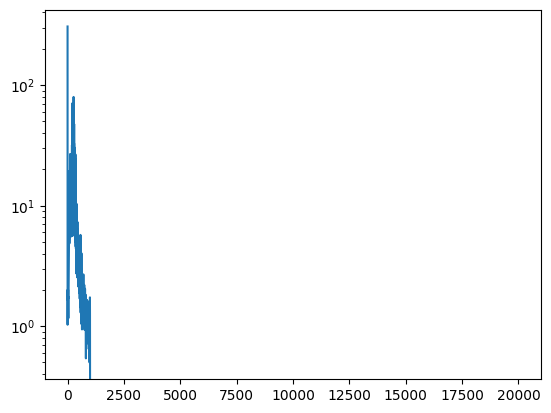

In [26]:
plt.plot(error_log)
plt.semilogy()
plt.show()

In [27]:
Y1 = Y[:,:n_pixels]
Y2 = Y[:,n_pixels:]

image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(Y1[entry,:]+Y2[entry,:])
    image_array += [snapshot]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
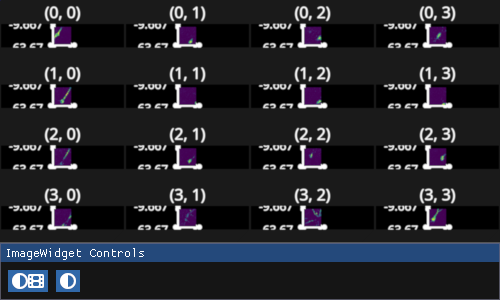

In [28]:
iw = fpl.ImageWidget(image_array, cmap="viridis", histogram_widget=False)
for subplot in iw.figure:
    subplot.toolbar = False

iw.show()

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
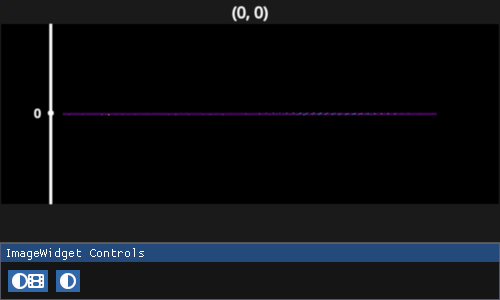

In [29]:
fpl.ImageWidget(Y1, cmap="viridis", histogram_widget=False).show()